# **Introduction to PyTorch**
### Training a CNN to Recognize Handwritten Digits with **MNIST**

---

In this notebook, we will build and train a simple Convolutional Neural Network (CNN) using `PyTorch` to classify handwritten digits from the MNIST dataset.

The workflow includes:

1. Importing the required `PyTorch libraries`
2. Defining the i`mage preprocessing pipeline`
3. Loading the `MNIST` dataset
4. `Exploring and visualizing` sample images
5. Creating data loaders for `batch processing`
6. Building the `CNN architecture`
7. `Training` the model
8. `Evaluating` model performance
9. `Saving` the trained model
10. `Visualizing` training metrics and results


### **1. Import our libaries and modules**

We import PyTorch by importing ```torch```. We'll be using **torchvision** which is a PyTorch package that consists of popular datasets, model acrhitectures and common image transformations.

In [1]:
# Import PyTorch
import torch

# We use torchvision to get our dataset and useful image transformations
import torchvision
import torchvision.transforms as transforms

# Import PyTorch's optimization libary and nn
# nn is used as the basic building block for our Network graphs
import torch.optim as optim
import torch.nn as nn

# Are we using our GPU?
print("GPU available: {}".format(torch.cuda.is_available()))

GPU available: True


#### If GPU is available set device = ```'cuda'``` if not set device = ```'cpu'```

In [2]:
if torch.cuda.is_available():
  device = 'cuda'
else:
  device = 'cpu'

### **2. Building the Transformation Pipeline**

---

To prepare our images for the neural network, we apply a series of transformations using `transforms.Compose()`.

- `transforms.ToTensor()` converts images into PyTorch tensors.
- `transforms.Normalize()` scales the pixel values to a standardized range.
- Using `(0.5,), (0.5,)` for grayscale images maps pixel values from `[0, 1]` to `[-1, 1]`.
- For RGB images, use `(0.5, 0.5, 0.5)` for both the mean and standard deviation of the three color channels.

**Why normalize?**
- Keeps input values on a consistent scale.
- Improves training stability and convergence speed.
- Helps the model learn more effectively.

MNIST images are grayscale with dimensions `28 × 28`, and their original pixel values range from `0` to `255`.

In [3]:
# Transform to a PyTorch tensors and the normalize our valeus between -1 and +1
transform = transforms.Compose([transforms.ToTensor(),
                               transforms.Normalize((0.5, ), (0.5, )) ])

### **3. Loading the MNIST Dataset with torchvision**


---

The MNIST dataset is loaded using `torchvision.datasets.MNIST`, providing access to both training and testing images.

**Note:**

Although a transform is passed when creating the dataset, it is **not immediately applied** to every image.

Instead, the transform is executed only **when an image is retrieved from the dataset** (for example, by the DataLoader when creating a batch). As a result:

- The original MNIST images **remain unchanged in memory**.
- Each image is transformed only **when it is requested**.
- During training, transformed copies **are created on-the-fly for each batch**.

This approach is more memory efficient because the entire dataset does not need to be preprocessed and stored ahead of time.

In
`torchvision.datasets.MNIST('mnist', ...`

PyTorch does not immediately convert and normalize all 60,000 images.

Instead, when the DataLoader requests an image:


Python
```text
image, label = train_dataset[0]
```
PyTorch:

1.   Loads the original image.
2.   Applies ToTensor().
3.   Applies Normalize().
4.   Returns the transformed image.



This happens every time a sample is accessed, which is why the original dataset is never modified.

In [4]:
# Load our Training Data and specify what transform to use when loading
trainset = torchvision.datasets.MNIST('mnist',
                                      train = True,
                                      download = True,
                                      transform = transform)

# Load our Test Data and specify what transform to use when loading
testset = torchvision.datasets.MNIST('mnist',
                                     train = False,
                                     download = True,
                                     transform = transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 480kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.42MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.72MB/s]


## **About Training and Evaluation Data**

The MNIST dataset is divided into two parts:

- **Training Set**: Used to train the model and update its weights.
- **Validation/Test Set**: Used to measure how well the model performs on unseen data.

During training, the model is periodically evaluated on the validation data to track its performance and detect potential overfitting.

**`Machine Learning Best Practice`**

In many projects, a separate **test set** is reserved until training is complete. This provides an **unbiased estimate** of how well the model will **generalize to new, unseen data**.

For the MNIST dataset, only training and test splits are provided. Therefore, the test set is commonly used for both validation during training and final model evaluation.

### 4. Exploring the Dataset
---
Before training, it is useful to inspect the **training** and **test** datasets to understand:

- The **number of images** in each split.
- The **dimensions** of the input images.
- The overall **structure** of the dataset.

Performing these checks helps ensure the data has been loaded correctly and is ready for training.

In [5]:
# We have 60,000 Image samples for our training data & 10,000 for our test data
# each 28 x 28 pixels, as they are grayscale, there is no 3rd dimension to our image
print(trainset.data.shape)
print(testset.data.shape)

torch.Size([60000, 28, 28])
torch.Size([10000, 28, 28])


### Visualizing Sample Digits
**bold text**
To better understand the dataset, the first **50 images** from the MNIST training set are displayed using **Matplotlib**.

Visualizing the data helps verify that the images have been loaded correctly and provides insight into the variety of handwritten digit styles present in the dataset. Each image is a **28 × 28 grayscale** representation of a digit between **0 and 9**.

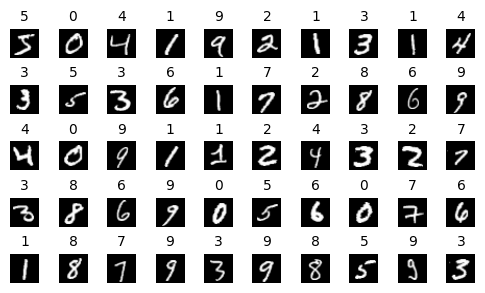

In [6]:
import matplotlib.pyplot as plt

# Display the first 50 images
fig, axes = plt.subplots(5, 10, figsize=(5, 3))

for i, ax in enumerate(axes.flat):
    image, label = trainset[i]

    ax.imshow(image.squeeze(), cmap='gray')
    ax.set_title(label, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

### **5. Creating the Data Loaders**

A **DataLoader** is responsible for loading the dataset in **mini-batches** during training (batch size = 128).

Processing data in batches is more memory-efficient than passing the entire dataset through the network at once.

- **`shuffle=True`** randomly rearranges the training data each epoch, helping ***prevent learning bias*** from the sample order.
- **`num_workers=0`** loads data using the main process (CPU cores). This is a good default setting and can be increased later to improve loading performance.

In [7]:
# Prepare train and test loader
trainloader = torch.utils.data.DataLoader(trainset,
                                           batch_size = 128,
                                           shuffle = True,
                                           num_workers = 0)

testloader = torch.utils.data.DataLoader(testset,
                                          batch_size = 128,
                                          shuffle = False,
                                          num_workers = 0)

### **Batch Data Loading & Inspection**

* **`iter(trainloader)`**: Converts the PyTorch `DataLoader` into an **iterator** to enable batch-by-batch retrieval.

* **`next(dataiter)`**: Fetches the **first batch** of data, splitting it into **`images`** (input tensors) and **`labels`** (target classes).

In [8]:
# We use the Python function iter to return an iterator for our train_loader object
dataiter = iter(trainloader)

# We use next to get the first batch of data from our iterator
images, labels = next(dataiter)

print(images.shape)
print(labels.shape)

torch.Size([128, 1, 28, 28])
torch.Size([128])


### **Visualizing a Batch of Training Images**

* **`torchvision.utils.make_grid(images)`**: Combines the batch of individual tensors into a single **image grid** so they can be plotted together.

The shape torch.Size([3, 482, 242]) represents the dimensions of the final combined grid tensor in PyTorch's standard channel-first format (C, H, W):

    3 (Channels): Represents the RGB color channels (Red, Green, and Blue).

    482 (Height) and 242 (Width): The total pixel dimensions of the assembled image grid.

Grid tensor shape: torch.Size([3, 482, 242])


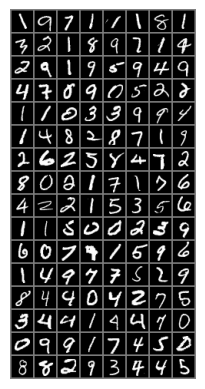

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision

# Helper function to unnormalize and display an image grid
def imshow(img: torch.Tensor) -> None:
    img = img / 2 + 0.5     # Unnormalize from [-1, 1] to [0, 1]
    npimg = img.numpy()

    # Transpose from PyTorch format (C, H, W) to Matplotlib format (H, W, C)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")
    plt.show()

# Fetch the first batch of training images using modern Python/PyTorch syntax
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Create a grid from the batch and display it
grid = torchvision.utils.make_grid(images)
print(f"Grid tensor shape: {grid.shape}")

# Display the image grid
imshow(grid)

### **6. Building the Model**

We use `nn.Sequential` for a clean, Keras-like model architecture.

#### **Convolution Layer (`nn.Conv2d`)**
```python
nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1)
```

in_channels: Input channels (1 for grayscale, 3 for RGB).

out_channels: Number of filters (32), which becomes the in_channels for the next layer.kernel_size:

Filter dimensions ($3 \times 3$).stride: Step size for the filter (default: 1).

padding: Zero-padding added around the input (set to 1).

#### **Max Pooling Layer** `(nn.MaxPool2d)`

```python
nn.MaxPool2d(2, 2)
```
halves both the height and width of the feature maps, compacting spatial dimensions while retaining essential features.

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQjns8CLoyBLv6JrEJZt5tk2W3q1yDzZJI6be_PPZ2aO3a1GAb2dFFXxXY&s=10)
CNN Architecture Overview. Source: GeeksforGeeks

### **What is `torch.nn.functional`?**

Usually imported as `import torch.nn.functional as F`, this module contains stateless functions (such as **activation functions**, **loss functions**, and **pooling**) rather than classes.

While it includes functions for **convolutions** and **linear layers**, those are typically handled better by other parts of the library like `nn.Module`.

In [11]:
import torch.nn as nn
import torch.nn.functional as F #

# Create our Model using a Python Class
class Net(nn.Module):
    def __init__(self):
        # super is a subclass of the nn.Module and inherits all its methods
        super(Net, self).__init__()

        # We define our layer objects here
        # Our first CNN Layer using 32 Fitlers of 3x3 size, with stride of 1 & padding of 0
        self.conv1 = nn.Conv2d(1, 32, 3)

        # Our second CNN Layer using 64 Fitlers of 3x3 size, with stride of 1 & padding of 0
        self.conv2 = nn.Conv2d(32, 64, 3)

        # Our Max Pool Layer 2 x 2 kernel of stride 2
        self.pool = nn.MaxPool2d(2, 2)


        # Fully connected layers
        # (Dimension calculation: 64 channels * flattened spatial dimensions)
        self.fc1 = nn.Linear(64 * 12 * 12, 128)

        # Our second Fully Connected Layer, connects the 128 nodes to 10 output nodes (our classes)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        # Forward propagation sequence: Conv1 -> ReLU -> Conv2 -> ReLU -> MaxPool -> Flatten -> FC1 -> FC2
        x = F.relu(self.conv1(x))
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten the feature maps into a 2D tensor for the linear layer
        x = x.view(-1, 64 * 12 * 12)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model and move it to the target device (e.g., CUDA or CPU)
net = Net().to(device)

#### **Same code as above but without the distracting comments**

In [15]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3)
        self.conv2 = nn.Conv2d(32, 64, 3)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 12 * 12, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 64 * 12 * 12)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

net = Net().to(device)


print(net)

Net(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=9216, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


### **7. Defining a Loss Function and Optimizer**

We need to choose a loss function to measure the model's error and an optimizer to update the model weights based on gradients.

1. **Loss Function**: `nn.CrossEntropyLoss` is standard for multi-class classification problems.
2. **Optimizer**: Stochastic Gradient Descent (`optim.SGD`) with a learning rate (`lr`) of `0.001` and a `momentum` of `0.9`.

In [16]:
# We import our optimizer function
import torch.optim as optim

# We use Cross Entropy Loss as our loss function
criterion = nn.CrossEntropyLoss()

# For our gradient descent algorthim or Optimizer
# We use Stochastic Gradient Descent (SGD) with a learning rate of 0.001
# We set the momentum to be 0.9
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

### **8. Training Our Model**

With our model architecture, loss function, and optimizer ready, we execute the standard training loop. The training process iterates through epochs and mini-batches, performing five core steps per batch:

1. **Forward Pass**: Pass input data through the network to generate predictions.
2. **Compute Loss**: Measure the error between predictions and true labels using our criterion.
3. **Zero Gradients**: Clear out old gradients from the previous batch (`optimizer.zero_grad()`).
4. **Backward Pass**: Compute new gradients via backpropagation (`loss.backward()`).
5. **Optimizer Step**: Update the model weights using the calculated gradients (`optimizer.step()`).

![](https://encrypted-tbn2.gstatic.com/licensed-image?q=tbn:ANd9GcS_2GH-lBAyvwBNXrLBK_k1F-eq-GXo1m0R7Jo1be7TcT-93sP1xRzeOZ6jop2wxI1qgyWcSFYic5UjoyA)

In [17]:
# We loop over the training dataset multiple times (each time is called an epoch)
epochs = 10

# Create some empty arrays to store logs
epoch_log = []
loss_log = []
accuracy_log = []

# Iterate for a specified number of epochs
for epoch in range(epochs):
    print(f'Starting Epoch: {epoch+1}...')

    # We keep adding or accumulating our loss after each mini-batch in running_loss
    running_loss = 0.0

    # We iterate through our trainloader iterator
    # Each cycle is a minibatch
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # Move our data to GPU
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Clear the gradients before training by setting to zero
        # Required for a fresh start
        optimizer.zero_grad()

        # Forward -> backprop + optimize
        outputs = net(inputs) # Forward Propagation
        loss = criterion(outputs, labels) # Get Loss (quantify the difference between the results and predictions)
        loss.backward() # Back propagate to obtain the new gradients for all nodes
        optimizer.step() # Update the gradients/weights

        # Print Training statistics - Epoch/Iterations/Loss/Accuracy
        running_loss += loss.item()
        if i % 50 == 49:    # show our loss every 50 mini-batches
            correct = 0 # Initialize our variable to hold the count for the correct predictions
            total = 0 # Initialize our variable to hold the count of the number of labels iterated

            # We don't need gradients for validation, so wrap in
            # no_grad to save memory
            with torch.no_grad():
                # Iterate through the testloader iterator
                for data in testloader:
                    images, labels = data
                    # Move our data to GPU
                    images = images.to(device)
                    labels = labels.to(device)

                    # Foward propagate our test data batch through our model
                    outputs = net(images)

                     # Get predictions from the maximum value of the predicted output tensor
                     # we set dim = 1 as it specifies the number of dimensions to reduce
                    _, predicted = torch.max(outputs.data, dim = 1)
                    # Keep adding the label size or length to the total variable
                    total += labels.size(0)
                    # Keep a running total of the number of predictions predicted correctly
                    correct += (predicted == labels).sum().item()

                accuracy = 100 * correct / total
                epoch_num = epoch + 1
                actual_loss = running_loss / 50
                print(f'Epoch: {epoch_num}, Mini-Batches Completed: {(i+1)}, Loss: {actual_loss:.3f}, Test Accuracy = {accuracy:.3f}%')
                running_loss = 0.0

    # Store training stats after each epoch
    epoch_log.append(epoch_num)
    loss_log.append(actual_loss)
    accuracy_log.append(accuracy)

print('Finished Training')

Starting Epoch: 1...
Epoch: 1, Mini-Batches Completed: 50, Loss: 2.263, Test Accuracy = 49.910%
Epoch: 1, Mini-Batches Completed: 100, Loss: 2.054, Test Accuracy = 66.240%
Epoch: 1, Mini-Batches Completed: 150, Loss: 1.478, Test Accuracy = 77.840%
Epoch: 1, Mini-Batches Completed: 200, Loss: 0.809, Test Accuracy = 84.690%
Epoch: 1, Mini-Batches Completed: 250, Loss: 0.544, Test Accuracy = 87.680%
Epoch: 1, Mini-Batches Completed: 300, Loss: 0.457, Test Accuracy = 88.680%
Epoch: 1, Mini-Batches Completed: 350, Loss: 0.409, Test Accuracy = 89.820%
Epoch: 1, Mini-Batches Completed: 400, Loss: 0.370, Test Accuracy = 90.050%
Epoch: 1, Mini-Batches Completed: 450, Loss: 0.356, Test Accuracy = 90.050%
Starting Epoch: 2...
Epoch: 2, Mini-Batches Completed: 50, Loss: 0.356, Test Accuracy = 90.710%
Epoch: 2, Mini-Batches Completed: 100, Loss: 0.337, Test Accuracy = 91.120%
Epoch: 2, Mini-Batches Completed: 150, Loss: 0.336, Test Accuracy = 91.430%
Epoch: 2, Mini-Batches Completed: 200, Loss: 0.2

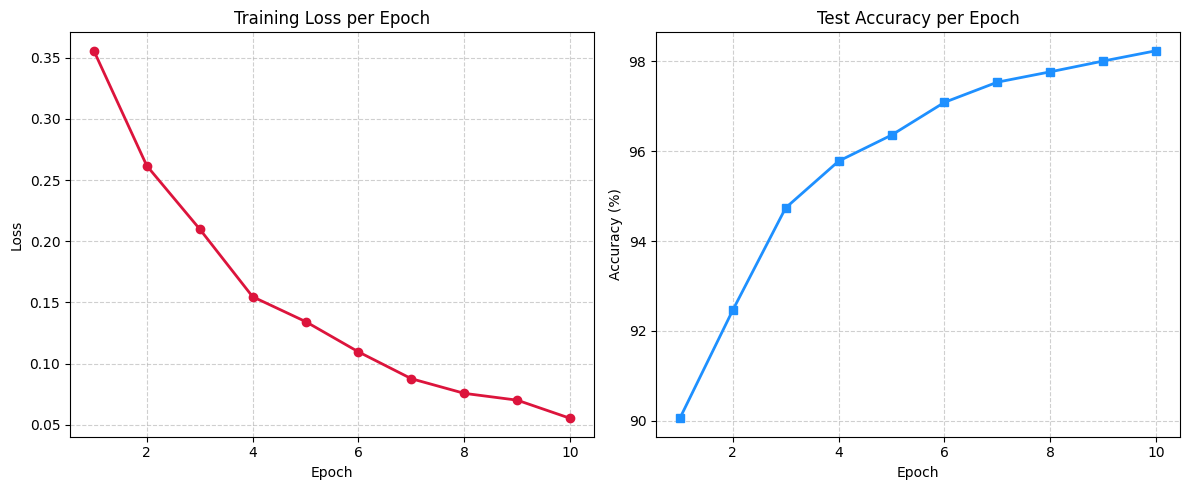

In [18]:
import matplotlib.pyplot as plt

# Create a figure with two subplots: one for Loss and one for Accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot Training Loss
ax1.plot(epoch_log, loss_log, marker='o', color='crimson', linewidth=2)
ax1.set_title('Training Loss per Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot Test Accuracy
ax2.plot(epoch_log, accuracy_log, marker='s', color='dodgerblue', linewidth=2)
ax2.set_title('Test Accuracy per Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## **9. Saving Our Model**

We use the ```torch.save()``` function to save our model.

```net.state_dict()``` saves our model weights in a dictionary format.

In [19]:
PATH = './mnist_cnn_net.pth'
torch.save(net.state_dict(), PATH)

### **Let's look at some images from your Test Data and view their Ground Truth labels**

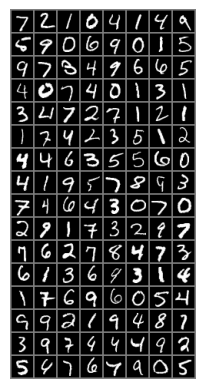

Ground Truth: 7     2     1     0     4     1     4     9     5     9     0     6     9     0     1     5     9     7     3     4     9     6     6     5     4     0     7     4     0     1     3     1     3     4     7     2     7     1     2     1     1     7     4     2     3     5     1     2     4     4     6     3     5     5     6     0     4     1     9     5     7     8     9     3     7     4     6     4     3     0     7     0     2     9     1     7     3     2     9     7     7     6     2     7     8     4     7     3     6     1     3     6     9     3     1     4     1     7     6     9     6     0     5     4     9     9     2     1     9     4     8     7     3     9     7     4     4     4     9     2     5     4     7     6     7     9     0     5    


In [21]:
# Loading one mini-batch
dataiter = iter(testloader)
images, labels = next(dataiter)

# Display images using torchvision's utils.make_grid()
imshow(torchvision.utils.make_grid(images))

classes = ('0', '1', '2', '3', '4', '5', '6', '7', '8', '9')
print('Ground Truth:', ' '.join(f'{classes[labels[j]]:5s}' for j in range(len(labels))))

### **Let's reload the model we just saved**

In [22]:
# Create an instance of the model and move it (memory and operations) to the CUDA device.
net = Net()
net.to(device)

# Load weights from the specified path
net.load_state_dict(torch.load(PATH))

<All keys matched successfully>

#### **Getting Predictions**

Note when working with tensors on the GPU, we have to convert it back to a numpy array to perform python operations on it.

```your_tensor.cpu().numpy()```

In [24]:
## Let's forward propagate one mini-batch and get the predicted outputs
# We use the Python function iter to return an iterator for our train_loader object
test_iter = iter(testloader)

# We use next to get the first batch of data from our iterator
images, labels = next(test_iter)

# Move our data to GPU
images = images.to(device)
labels = labels.to(device)

outputs = net(images)

# Get the class predictions using torch.max
_, predicted = torch.max(outputs, 1)

# Print our 128 predictions
print('Predicted: ', ''.join('%1s' % predicted[j].cpu().numpy() for j in range(128)))

Predicted:  72104149590690159734966540740131347271211742351244635560419578937464307029173297762784736136931417696054992194873974449254767905


#### **Showing our Test Accuracy again**

In [25]:
correct = 0
total = 0

with torch.no_grad():
    for data in testloader:
        images, labels = data
        # Move our data to GPU
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy of the network on the 10000 test images: {accuracy:.3}%')

Accuracy of the network on the 10000 test images: 98.2%


### **Observations**

* **CPU vs. GPU Performance**: If you test this network on the CPU (by setting `device = torch.device('cpu')`), you may not notice a dramatic difference in training speed. For a small network like this, the overhead of data transfer between the host and device often outweighs the compute time. However, for larger or deeper architectures, the speedup provided by a GPU is substantial.

In short, think of it as switching your model from `studying mode` to `test mode`:

  **`net.eval()`**: Turns off training-only features (like random dropouts) so the model gives consistent, reliable answers instead of practicing.

  **`torch.no_grad()`**: Stops tracking how weights change (gradients), which saves memory and speeds up testing since the model isn't learning anymore.

In [29]:
from google.colab.patches import cv2_imshow
net.eval()

# We don't need gradients for validation, so wrap in
# no_grad to save memory
with torch.no_grad():
    for data in testloader:
        images, labels = data

        # Move our data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Get our outputs
        outputs = net(images)

        # use torch.argmax() to get the predictions, argmax is used for long_tensors
        predictions = torch.argmax(outputs, dim=1)

        # For test data in each batch we identify when predictions did not match the label
        # then we print out the actual ground truth
        for i in range(data[0].shape[0]):
            pred = predictions[i].item()
            label = labels[i]
            if(label != pred) and i < 3:
                print(f'Actual Label: {pred}, Predicted Label: {label}')
                img = np.reshape(images[i].cpu().numpy(),[28,28])
                cv2_imshow(np.uint8(img))

Actual Label: 1, Predicted Label: 2


Actual Label: 2, Predicted Label: 1


Actual Label: 7, Predicted Label: 9


Actual Label: 0, Predicted Label: 4


Actual Label: 6, Predicted Label: 5


In [30]:
nb_classes = 10

confusion_matrix = torch.zeros(nb_classes, nb_classes)

with torch.no_grad():
    for i, (inputs, classes) in enumerate(testloader):
        inputs = inputs.to(device)
        classes = classes.to(device)
        outputs = net(inputs)
        _, preds = torch.max(outputs, 1)
        for t, p in zip(classes.view(-1), preds.view(-1)):
                confusion_matrix[t.long(), p.long()] += 1


tensor([[9.7400e+02, 0.0000e+00, 2.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00,
         1.0000e+00, 1.0000e+00, 1.0000e+00, 0.0000e+00],
        [0.0000e+00, 1.1300e+03, 1.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00,
         2.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00],
        [3.0000e+00, 5.0000e+00, 1.0090e+03, 3.0000e+00, 3.0000e+00, 0.0000e+00,
         1.0000e+00, 5.0000e+00, 3.0000e+00, 0.0000e+00],
        [0.0000e+00, 0.0000e+00, 1.0000e+00, 1.0000e+03, 0.0000e+00, 2.0000e+00,
         0.0000e+00, 3.0000e+00, 2.0000e+00, 2.0000e+00],
        [1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 9.7200e+02, 0.0000e+00,
         0.0000e+00, 1.0000e+00, 2.0000e+00, 6.0000e+00],
        [2.0000e+00, 0.0000e+00, 0.0000e+00, 4.0000e+00, 0.0000e+00, 8.7600e+02,
         4.0000e+00, 1.0000e+00, 2.0000e+00, 3.0000e+00],
        [7.0000e+00, 3.0000e+00, 0.0000e+00, 0.0000e+00, 3.0000e+00, 4.0000e+00,
         9.3900e+02, 0.0000e+00, 2.0000e+00, 0.0000e+00],
        [2.0000e+00, 6.0000

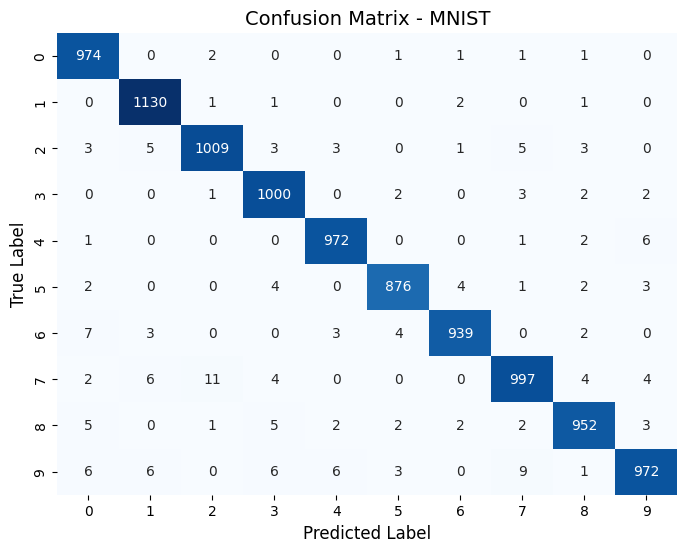

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert the PyTorch confusion matrix tensor to a NumPy array
cm_np = confusion_matrix.numpy()

plt.figure(figsize=(8, 6))
sns.heatmap(cm_np, annot=True, fmt='g', cmap='Blues', cbar=False,
            xticklabels=range(10), yticklabels=range(10))

plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - MNIST', fontsize=14)
plt.show()

In [33]:
# Calculate and print accuracy for each class directly from the confusion matrix
for i in range(nb_classes):
    correct = confusion_matrix[i, i].item()
    total = confusion_matrix[i, :].sum().item()

    if total > 0:
        class_accuracy = 100 * correct / total
        print(f'Accuracy of digit {i} : {class_accuracy:.3f}%')
    else:
        print(f'Accuracy of digit {i} : N/A (no samples)')

Accuracy of digit 0 : 99.388%
Accuracy of digit 1 : 99.559%
Accuracy of digit 2 : 97.771%
Accuracy of digit 3 : 99.010%
Accuracy of digit 4 : 98.982%
Accuracy of digit 5 : 98.206%
Accuracy of digit 6 : 98.017%
Accuracy of digit 7 : 96.984%
Accuracy of digit 8 : 97.741%
Accuracy of digit 9 : 96.333%
